## Environment Setup & Optical Flow Pipeline

In [1]:
import os
import time
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoImageProcessor, AutoModelForDepthEstimation
from ultralytics import YOLO

# Hardware device configuration (Apple Silicon MPS Acceleration)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using acceleration device: {device}")

# Define relative paths based on repository layout
PROJECT_ROOT = os.path.abspath("..")
IMAGE_DIR = os.path.join(PROJECT_ROOT, "v1.0-mini", "samples", "CAM_FRONT")
OUTPUT_DIR = os.path.join(PROJECT_ROOT, "outputs", "fusion_results")
EXCEL_PATH = os.path.join(PROJECT_ROOT, "notebooks", "experiment_results.xlsx")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Load Segmentation Model (YOLOv11-Nano) & Depth Model
seg_model = YOLO("yolo11n-seg.pt")
depth_encoder = "depth-anything/Depth-Anything-V2-Small-hf"
depth_processor = AutoImageProcessor.from_pretrained(depth_encoder)
depth_model = AutoModelForDepthEstimation.from_pretrained(depth_encoder).to(
    device
)

# Taxonomy separation
DYNAMIC_CLASSES = {0: "person", 1: "bicycle", 2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}
STATIC_CLASSES = {11: "stop sign", 13: "bench"}

CLASS_WEIGHTS = {
    0: 1.00,  # Pedestrian
    1: 0.85,  # Bicycle
    2: 0.55,  # Car
    3: 0.85,  # Motorcycle
    5: 0.70,  # Bus
    7: 0.70,  # Truck
    11: 0.30,  # Static Barrier / Sign
}
DEFAULT_WEIGHT = 0.20

/opt/anaconda3/envs/av_risk/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using acceleration device: mps


Loading weights: 100%|██████████| 287/287 [00:00<00:00, 8460.30it/s]


## Two-Frame Dynamic/Static Separation Engine

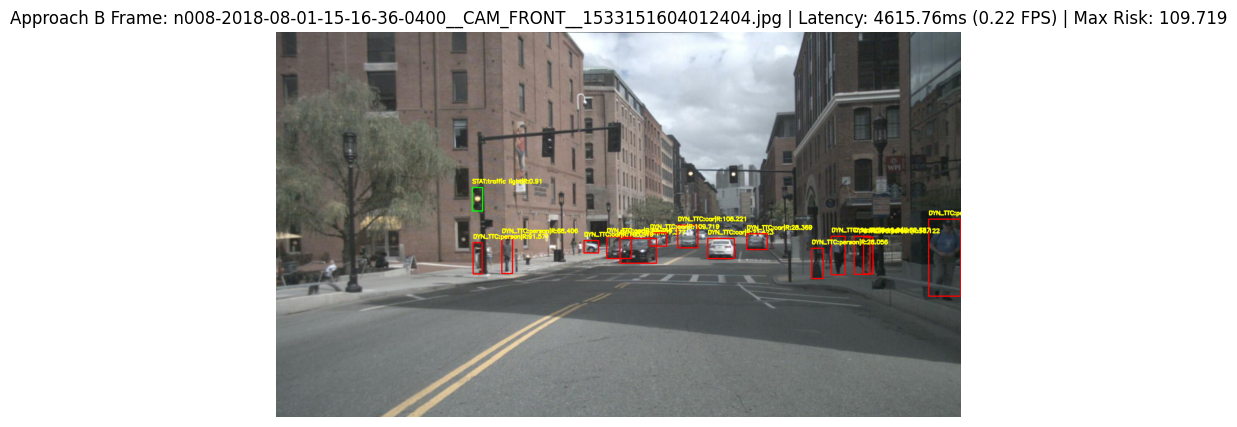

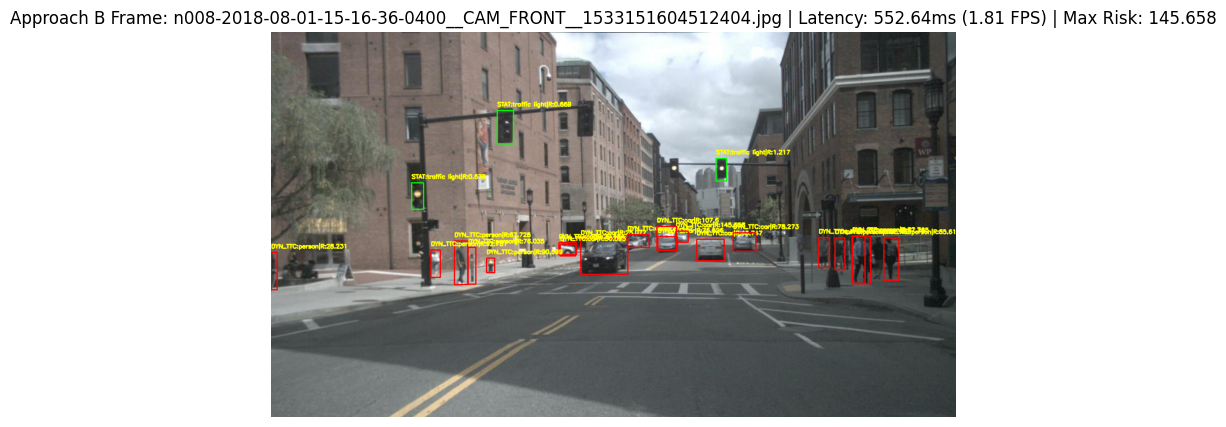

In [2]:
# Select 2 consecutive sequential frames for motion computation
all_frames = sorted(
    [
        f
        for f in os.listdir(IMAGE_DIR)
        if f.endswith(".jpg") or f.endswith(".png")
    ]
)
frame_pairs = [(all_frames[i], all_frames[i + 1]) for i in range(2)]

records_b = []

for idx, (f_prev, f_curr) in enumerate(frame_pairs):
    path_prev = os.path.join(IMAGE_DIR, f_prev)
    path_curr = os.path.join(IMAGE_DIR, f_curr)

    img_prev = cv2.imread(path_prev)
    img_curr = cv2.imread(path_curr)
    h, w, _ = img_curr.shape

    start_time = time.time()

    # Step 1: Compute Dense Optical Flow (Farnebäck) between Frame t and t+1
    gray_prev = cv2.cvtColor(img_prev, cv2.COLOR_BGR2GRAY)
    gray_curr = cv2.cvtColor(img_curr, cv2.COLOR_BGR2GRAY)

    flow = cv2.calcOpticalFlowFarneback(
        gray_prev,
        gray_curr,
        None,
        pyr_scale=0.5,
        levels=3,
        winsize=15,
        iterations=3,
        poly_n=5,
        poly_sigma=1.2,
        flags=0,
    )
    flow_magnitude, _ = cv2.cartToPolar(flow[..., 0], flow[..., 1])

    # Step 2: YOLO Segmentation on current frame
    seg_results = seg_model.predict(
        source=path_curr, device=device, verbose=False
    )[0]

    # Step 3: Depth Anything V2 on current frame
    img_rgb = cv2.cvtColor(img_curr, cv2.COLOR_BGR2RGB)
    inputs = depth_processor(images=img_rgb, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = depth_model(**inputs)
        pred_depth = outputs.predicted_depth

    depth_map = (
        torch.nn.functional.interpolate(
            pred_depth.unsqueeze(1),
            size=(h, w),
            mode="bicubic",
            align_corners=False,
        )
        .squeeze()
        .cpu()
        .numpy()
    )

    depth_norm = (depth_map - depth_map.min()) / (
        depth_map.max() - depth_map.min() + 1e-6
    )

    # Step 4: Separate Risk Routing (Static Channel vs Dynamic Channel)
    annotated = img_rgb.copy()
    max_risk = 0.0
    obj_count = 0

    if seg_results.masks is not None and seg_results.boxes is not None:
        masks = seg_results.masks.data.cpu().numpy()
        boxes = seg_results.boxes

        for i, mask in enumerate(masks):
            cls_id = int(boxes.cls[i].item())
            class_name = seg_model.names[cls_id]
            w_class = CLASS_WEIGHTS.get(cls_id, DEFAULT_WEIGHT)

            bin_mask = cv2.resize(mask, (w, h)) > 0.5
            if np.sum(bin_mask) == 0:
                continue

            obj_count += 1
            obj_depth = np.median(depth_norm[bin_mask])
            obj_motion = np.median(flow_magnitude[bin_mask])

            # ROUTING LOGIC: Dynamic Channel vs Static Channel
            if cls_id in DYNAMIC_CLASSES:
                # Dynamic Hazard Metric: Time-To-Collision (TTC) approximation
                # High relative optical flow toward camera reduces TTC -> increases risk
                v_rel = max(obj_motion, 1e-3)
                ttc = obj_depth / v_rel
                risk_score = round(float(w_class * (1.0 / (ttc + 1e-3))), 3)
                label_prefix = "DYN_TTC"
            else:
                # Static Hazard Metric: Direct Proximity / Braking Margin
                risk_score = round(float(w_class * (1.0 / (obj_depth + 1e-3))), 3)
                label_prefix = "STAT"

            if risk_score > max_risk:
                max_risk = risk_score

            # Draw visual box
            box = boxes.xyxy[i].cpu().numpy().astype(int)
            color = (255, 0, 0) if cls_id in DYNAMIC_CLASSES else (0, 255, 0)
            cv2.rectangle(
                annotated, (box[0], box[1]), (box[2], box[3]), color, 2
            )
            cv2.putText(
                annotated,
                f"{label_prefix}:{class_name}|R:{risk_score}",
                (box[0], max(box[1] - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                (255, 255, 0),
                2,
            )

    latency_ms = round((time.time() - start_time) * 1000, 2)
    fps = round(1000 / latency_ms, 2)

    # Plot Visualisation
    plt.figure(figsize=(10, 5))
    plt.imshow(annotated)
    plt.title(
        f"Approach B Frame: {f_curr} | Latency: {latency_ms}ms ({fps} FPS) | Max Risk: {max_risk}"
    )
    plt.axis("off")
    plt.show()

    # Save output image
    cv2.imwrite(
        os.path.join(OUTPUT_DIR, f"approach_b_{f_curr}"),
        cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR),
    )

    records_b.append({
        "Exp_ID": f"EXP_FUSION_B_{int(time.time())}",
        "Timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
        "Task": "Approach B - Motion-Aware Dynamic/Static",
        "Segmentation_Model": "YOLOv11-Nano",
        "Depth_Model": "Depth-Anything-V2-Small",
        "Sample_Image": f_curr,
        "Total_Objects": obj_count,
        "Max_Risk_Score": max_risk,
        "Latency_ms": latency_ms,
        "FPS": fps,
        "Device": str(device),
    })

## Save Approach B Benchmark Data

In [3]:
df_b = pd.DataFrame(records_b)

if os.path.exists(EXCEL_PATH):
    df_existing = pd.read_excel(EXCEL_PATH)
    df_final = pd.concat([df_existing, df_b], ignore_index=True)
else:
    df_final = df_b

df_final.to_excel(EXCEL_PATH, index=False)
print(f"Successfully appended Approach B metrics to {EXCEL_PATH}")

df_b[
    [
        "Sample_Image",
        "Total_Objects",
        "Max_Risk_Score",
        "Latency_ms",
        "FPS",
        "Device",
    ]
]

Successfully appended Approach B metrics to /Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/notebooks/experiment_results.xlsx


,Sample_Image,Total_Objects,Max_Risk_Score,Latency_ms,FPS,Device
0,n008-2018-08-01-15-16-36-0400__CAM_FRONT__1533...,15,109.719,4615.76,0.22,mps
1,n008-2018-08-01-15-16-36-0400__CAM_FRONT__1533...,22,145.658,552.64,1.81,mps
